### <b> Objectives</b>
By the end of this notebook, you should be able to:
1. <b>Measure price distribution:</b> Calculate mean, median, minimum, maximum, standard deviation, and quartiles.
2. <b>Detect pricing patterns:</b> Understand whether smartphone prices are concentrated in lower, middle, or premium ranges.
3. <b>Compare brands:</b> Identify brands with the highest average and median prices.
4. <b>Analyze relationships:</b> Explore how price relates to RAM, battery capacity, and 5G availability.
5. <b>Visualize insights:</b> Create histograms, boxplots, and comparison charts.
6. <b>Communicate findings:</b> Convert analysis into evidence-based business insights.

Import libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

Load the cleaned dataset

In [4]:
from pathlib import Path

data_path = Path("../data/processed/smartphones_cleaned.csv")
df = pd.read_csv(data_path)

print("Dataset shape: ",df.shape)
print("Number Of smartphones:",len(df))
display(df.head())

Dataset shape:  (980, 22)
Number Of smartphones: 980


,brand_name,model,price,avg_rating,5G_or_not,processor_brand,num_cores,processor_speed,battery_capacity,fast_charging_available,...,internal_memory,screen_size,refresh_rate,num_rear_cameras,os,primary_camera_rear,primary_camera_front,extended_memory_available,resolution_height,resolution_width
0,apple,Apple iPhone 11,38999,7.30,0,bionic,6.00,2.65,"3,110.00",0,...,64,6.10,60,2,ios,12.00,12.00,0,1792,828
1,apple,Apple iPhone 11 (128GB),46999,7.50,0,bionic,6.00,2.65,"3,110.00",0,...,128,6.10,60,2,ios,12.00,12.00,0,1792,828
2,apple,Apple iPhone 11 Pro Max,109900,7.70,0,bionic,6.00,2.65,"3,500.00",1,...,64,6.50,60,3,ios,12.00,12.00,0,2688,1242
3,apple,Apple iPhone 12,51999,7.40,1,bionic,6.00,3.10,"5,000.00",0,...,64,6.10,60,2,ios,12.00,12.00,0,2532,1170
4,apple,Apple iPhone 12 (128GB),55999,7.50,1,bionic,6.00,3.10,"5,000.00",0,...,128,6.10,60,2,ios,12.00,12.00,0,2532,1170


In [5]:
df.isna().sum()

brand_name                     0
model                          0
price                          0
avg_rating                   101
5G_or_not                      0
processor_brand                0
num_cores                      0
processor_speed                0
battery_capacity               0
fast_charging_available        0
fast_charging                211
ram_capacity                   0
internal_memory                0
screen_size                    0
refresh_rate                   0
num_rear_cameras               0
os                             0
primary_camera_rear            0
primary_camera_front           5
extended_memory_available      0
resolution_height              0
resolution_width               0
dtype: int64

Inspect the price column

In [7]:
print("Price Data Type:",df["price"].dtype)
print("Missing prices:",df["price"].isna().sum())
print("Unique prices:",df["price"].nunique())

display(df["price"].describe())

Price Data Type: int64
Missing prices: 0
Unique prices: 379


count       980.00
mean     32,520.50
std      39,531.81
min       3,499.00
25%      12,999.00
50%      19,994.50
75%      35,491.50
max     650,000.00
Name: price, dtype: float64

Questions to answer:
- What is the cheapest smartphone?
- What is the most expensive smartphone?
- How many distinct prices exist?
- Are any prices missing?

In [10]:
price_stats = pd.Series({
    "Count": df["price"].count(),
    "Mean": df["price"].mean(),
    "Median":df["price"].median(),
    "Minimum":df["price"].min(),
    "Maximum":df["price"].max(),
    "Standard Diviation": df["price"].std(),
    "25th Percent": df["price"].quantile(0.25),
    "75th Percent":df["price"].quantile(0.75)
})
display(price_stats.to_frame("Data"))

,Data
Count,980.00
Mean,"32,520.50"
Median,"19,994.50"
Minimum,"3,499.00"
Maximum,"650,000.00"
Standard Diviation,"39,531.81"
25th Percent,"12,999.00"
75th Percent,"35,491.50"


If the mean is much higher than the median, expensive smartphones may be pulling the average upward.

#### Inter Quantile Range

In [11]:
q1 = df["price"].quantile(0.25)
q3 = df["price"].quantile(0.75)

iqr = q3 - q1
print("IQR: ",iqr)

IQR:  22492.5


Plot the price distribution

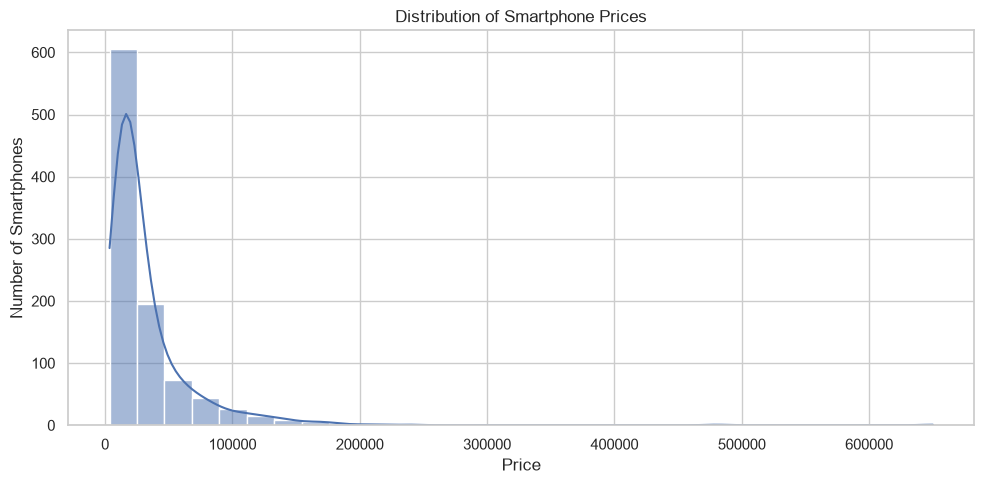

In [17]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="price", bins=30, kde=True)

plt.title("Distribution of Smartphone Prices")
plt.xlabel("Price")
plt.ylabel("Number of Smartphones")
plt.tight_layout()
plt.show()

Detect potential price outliers

In [18]:
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

potential_outliers = df[
    (df["price"] < lower_bound) |
    (df["price"] > upper_bound)
].sort_values("price", ascending=False)

print("Lower IQR bound:", lower_bound)
print("Upper IQR bound:", upper_bound)
print("Potential outlier count:", len(potential_outliers))

display(
    potential_outliers[["brand_name", "model", "price"]].head(15)
)

Lower IQR bound: -20739.75
Upper IQR bound: 69230.25
Potential outlier count: 107


,brand_name,model,price
732,vertu,Vertu Signature Touch,650000
909,xiaomi,Xiaomi Redmi K20 Pro Signature Edition,480000
94,huawei,Huawei Mate 50 RS Porsche Design,239999
91,huawei,Huawei Mate 30 RS Porsche Design,214990
873,xiaomi,Xiaomi Mi Mix Alpha,199990
32,apple,Apple iPhone 14 Pro Max (1TB),182999
19,apple,Apple iPhone 13 Pro Max (1TB),179900
29,apple,Apple iPhone 14 Pro (1TB),172999
34,apple,Apple iPhone 14 Pro Max (512GB),169900
95,huawei,Huawei Mate X,169000


Compare average prices by brand

In [19]:
brand_analysis = (
    df.groupby("brand_name")
      .agg(
          phone_count=("price", "count"),
          average_price=("price", "mean"),
          median_price=("price", "median"),
          minimum_price=("price", "min"),
          maximum_price=("price", "max")
      )
      .sort_values("median_price", ascending=False)
)

display(brand_analysis.head(15))

,phone_count,average_price,median_price,minimum_price,maximum_price
brand_name,,,,,
vertu,1,"650,000.00","650,000.00",650000,650000
royole,2,"129,999.00","129,999.00",109999,149999
leitz,1,"124,990.00","124,990.00",124990,124990
apple,46,"95,966.52","84,994.50",29990,182999
asus,7,"74,709.43","72,999.00",39999,107990
tesla,1,"69,999.00","69,999.00",69999,69999
sony,9,"60,570.67","69,990.00",15990,134999
sharp,1,"59,990.00","59,990.00",59990,59990
lg,3,"63,329.33","54,999.00",54999,79990


Plot the 10 brands with the highest median prices, restricting the comparison to brands with at least five phones in the dataset.

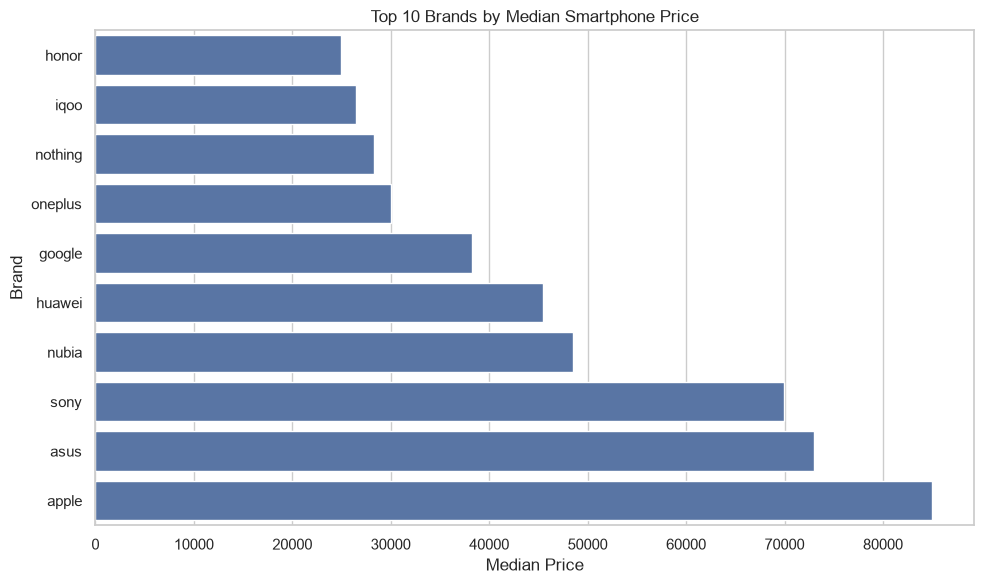

In [24]:
eligible_brands = brand_analysis[
    brand_analysis["phone_count"] >= 5
]

top_brands = eligible_brands.head(10).sort_values("median_price")

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_brands.reset_index(),
    x="median_price",
    y="brand_name"
)

plt.title("Top 10 Brands by Median Smartphone Price")
plt.xlabel("Median Price")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

The minimum-count rule reduces the chance of ranking a brand highly based on only one or two models.

Explore price versus RAM

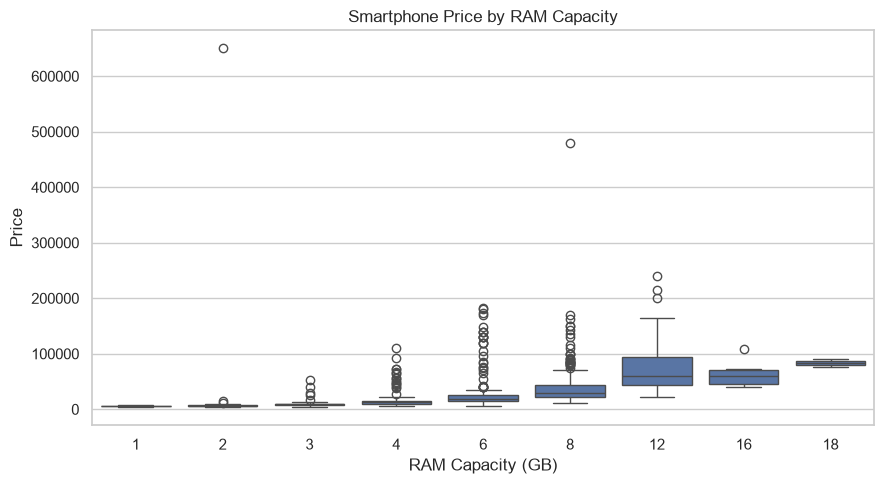

In [25]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="ram_capacity", y="price")

plt.title("Smartphone Price by RAM Capacity")
plt.xlabel("RAM Capacity (GB)")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

Ask yourself: Do higher-RAM phones tend to cost more? Are there exceptions?

Compare 5G and non-5G prices

In [26]:
df["network_type"] = df["5G_or_not"].map({
    0: "Non-5G",
    1: "5G"
})

network_summary = (
    df.groupby("network_type")["price"]
      .agg(["count", "mean", "median", "min", "max"])
)

display(network_summary)

,count,mean,median,min,max
network_type,,,,,
5G,549,"43,200.49","29,999.00",8990,214990
Non-5G,431,"18,916.53","12,787.00",3499,650000


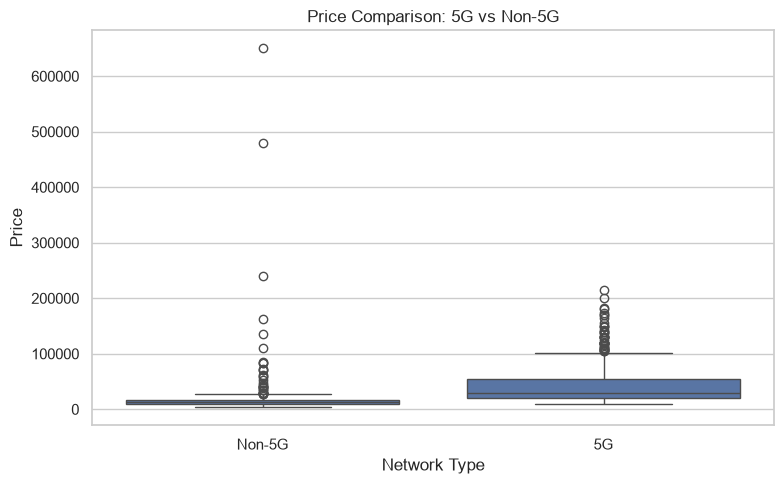

In [27]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="network_type", y="price")

plt.title("Price Comparison: 5G vs Non-5G")
plt.xlabel("Network Type")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

Compare medians and spreads. Remember that other features and brand positioning can also influence price.

Save a brand-level report

In [28]:
output_path = Path("../reports/brand_price_summary.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

brand_analysis.to_csv(output_path)

print("Report saved:", output_path)

Report saved: ..\reports\brand_price_summary.csv
